# 04. What if the assumptions change?

**Notebook version:** v1.0.0 (2026-10-20) &nbsp;|&nbsp; All numbers are illustrative, not from any real company or process.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## Why this matters
The inputs (defect rates, cost of a missed defect) are estimates. A good decision should hold up if the estimates are wrong. This notebook asks two questions:

1. If a missed defect becomes cheaper or more expensive, how does the best plan change?
2. Which assumption matters most?

In [2]:
from src.sensitivity import breakeven_scan, tornado
from src.search import describe_plan
scan = breakeven_scan(n_units=100_000)
scan["best_plan"] = scan["best_plan"].map(describe_plan)
scan.round(2)

,escape_cost_multiplier,escape_cost,best_plan,best_cost
0,0.10,50.0,Surface prep: none | Stack assembly: none | Fi...,3.16
1,0.25,125.0,Surface prep: none | Stack assembly: all | Fin...,6.89
2,0.50,250.0,Surface prep: none | Stack assembly: none | Fi...,8.80
3,1.00,500.0,Surface prep: none | Stack assembly: all | Fin...,9.55
4,2.00,1000.0,Surface prep: none | Stack assembly: all | Fin...,10.40
5,4.00,2000.0,Surface prep: none | Stack assembly: all | Fin...,12.11
6,8.00,4000.0,Surface prep: none | Stack assembly: all | Fin...,15.53


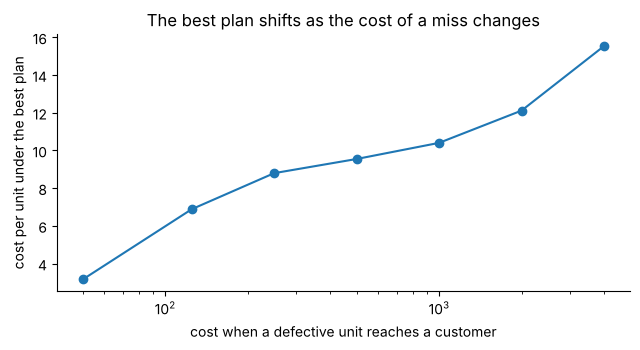

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(scan["escape_cost"], scan["best_cost"], "o-")
ax.set_xscale("log"); ax.set_xlabel("cost when a defective unit reaches a customer")
ax.set_ylabel("cost per unit under the best plan")
ax.set_title("The best plan shifts as the cost of a miss changes")
plt.tight_layout(); plt.show()

## Which assumption matters most?
Each input is changed by 50% up and down, one at a time (the detection rate is capped at 100%). The bar shows how much the best achievable cost moves.

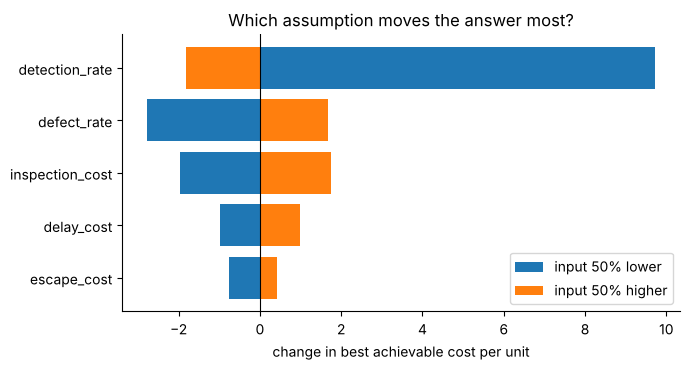

,input,case,best_plan,best_cost,change_vs_base,plan_changed
0,escape_cost,low,Surface prep: none | Stack assembly: none | Fi...,8.80,-0.75,True
1,escape_cost,high,Surface prep: none | Stack assembly: all | Fin...,9.98,0.43,False
2,detection_rate,low,Surface prep: none | Stack assembly: all | Fin...,19.26,9.71,False
3,detection_rate,high,Surface prep: none | Stack assembly: none | Fi...,7.74,-1.81,True
4,inspection_cost,low,Surface prep: none | Stack assembly: all | Fin...,7.59,-1.96,False
5,inspection_cost,high,Surface prep: none | Stack assembly: 10% | Fin...,11.29,1.74,True
6,delay_cost,low,Surface prep: none | Stack assembly: all | Fin...,8.57,-0.98,False
7,delay_cost,high,Surface prep: none | Stack assembly: all | Fin...,10.53,0.98,False
8,defect_rate,low,Surface prep: none | Stack assembly: none | Fi...,6.78,-2.77,True
9,defect_rate,high,Surface prep: none | Stack assembly: all | Fin...,11.23,1.68,False


In [4]:
tor = tornado(swing=0.5, n_units=100_000)
piv = tor.pivot(index="input", columns="case", values="change_vs_base")
piv["spread"] = piv["high"].abs() + piv["low"].abs()
piv = piv.sort_values("spread")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(piv.index, piv["low"], label="input 50% lower")
ax.barh(piv.index, piv["high"], label="input 50% higher")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("change in best achievable cost per unit")
ax.set_title("Which assumption moves the answer most?"); ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "docs" / "figures" / "what_if_tornado.png", dpi=150)
plt.show()
tor["best_plan"] = tor["best_plan"].map(describe_plan)
tor.round(2)

**Takeaway:** some assumptions barely move the answer and some change it a lot. Spend effort getting the important ones right. When the best plan *flips* between cases, that is a warning that the decision is sensitive to the estimate.

> These figures come from made-up inputs. They demonstrate the method, not any real company, product or process.